In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("D:/Sem_7/DMV Lab/city_day.csv")

In [3]:
print("First 5 rows:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns)

print("\nDataset Information:")
data.info()

print("\nMissing Values:")
print(data.isnull().sum())

First 5 rows:
        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  

Dataset Shape:
(29531, 16)

Column Names:
Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 

In [4]:
cleaned_data = data.dropna().copy()

print("\nCleaned Dataset:")
print(cleaned_data)

print("\nMissing Values After Cleaning:")
print(cleaned_data.isnull().sum())


Cleaned Dataset:
                City        Date  PM2.5    PM10    NO    NO2    NOx    NH3  \
2123       Amaravati  2017-11-25  81.40  124.50  1.44  20.50  12.08  10.72   
2124       Amaravati  2017-11-26  78.32  129.06  1.26  26.00  14.85  10.28   
2125       Amaravati  2017-11-27  88.76  135.32  6.60  30.85  21.77  12.91   
2126       Amaravati  2017-11-28  64.18  104.09  2.56  28.07  17.01  11.42   
2127       Amaravati  2017-11-29  72.47  114.84  5.23  23.20  16.59  12.25   
...              ...         ...    ...     ...   ...    ...    ...    ...   
29525  Visakhapatnam  2020-06-26   7.63   32.27  5.91  23.27  17.19  11.15   
29526  Visakhapatnam  2020-06-27  15.02   50.94  7.68  25.06  19.54  12.47   
29527  Visakhapatnam  2020-06-28  24.38   74.09  3.42  26.06  16.53  11.99   
29528  Visakhapatnam  2020-06-29  22.91   65.73  3.45  29.53  18.33  10.71   
29529  Visakhapatnam  2020-06-30  16.64   49.97  4.05  29.26  18.80  10.03   

         CO    SO2      O3  Benzene  Toluene 

In [5]:
cleaned_data['Date'] = pd.to_datetime(cleaned_data['Date'])

cleaned_data.sort_values(by='Date', inplace=True)

print("\nRelevant Variables:")
print("Date:", cleaned_data['Date'].head())
print("PM2.5:", cleaned_data['PM2.5'].head())
print("PM10:", cleaned_data['PM10'].head())
print("CO:", cleaned_data['CO'].head())
print("AQI:", cleaned_data['AQI'].head())


Relevant Variables:
Date: 10229   2015-01-01
10230   2015-01-02
10231   2015-01-03
10232   2015-01-04
10233   2015-01-05
Name: Date, dtype: datetime64[ns]
PM2.5: 10229    313.22
10230    186.18
10231     87.18
10232    151.84
10233    146.60
Name: PM2.5, dtype: float64
PM10: 10229    607.98
10230    269.55
10231    131.90
10232    241.84
10233    219.13
Name: PM10, dtype: float64
CO: 10229    15.20
10230     9.54
10231    10.61
10232    11.54
10233     9.20
Name: CO, dtype: float64
AQI: 10229    472.0
10230    454.0
10231    143.0
10232    319.0
10233    325.0
Name: AQI, dtype: float64


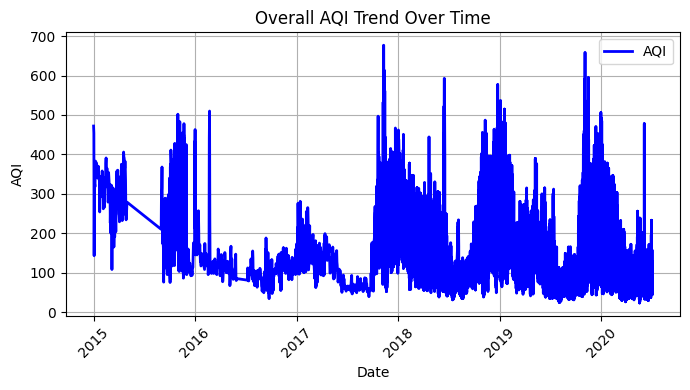

In [6]:
plt.figure(figsize=(7,4))
plt.plot(
    cleaned_data['Date'],
    cleaned_data['AQI'],
    label='AQI',
    color='blue',
    linewidth=2
)

plt.xlabel('Date')
plt.ylabel('AQI')
plt.title('Overall AQI Trend Over Time')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

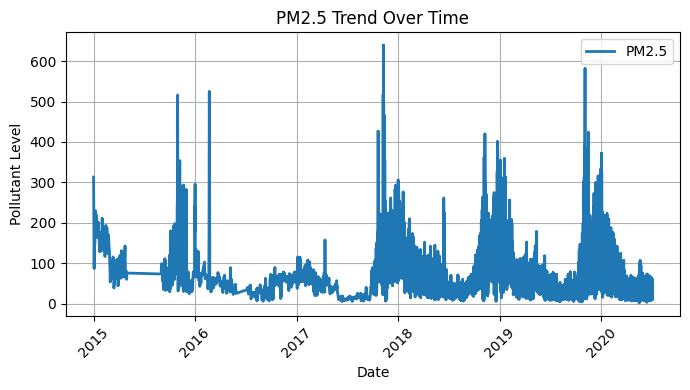

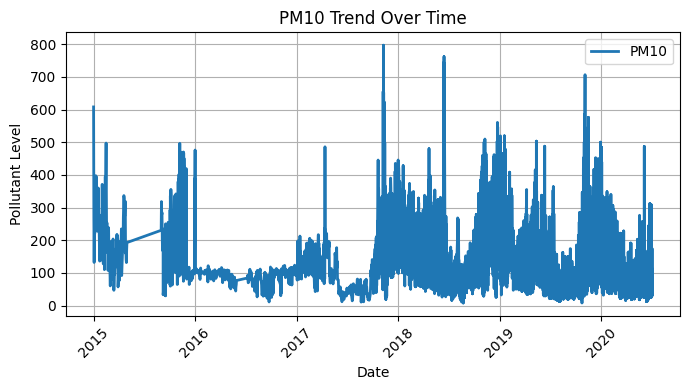

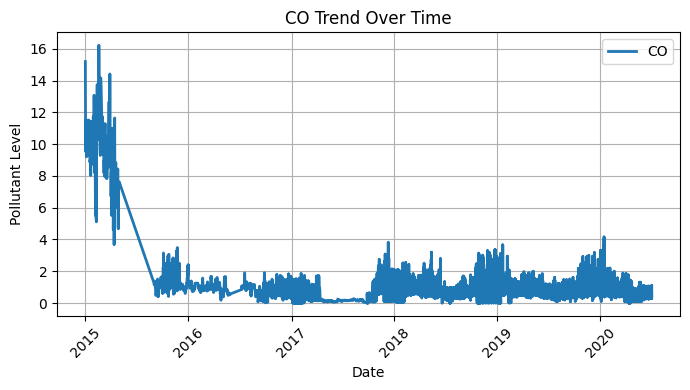

In [7]:
pollutants = ['PM2.5', 'PM10', 'CO']

for pollutant in pollutants:
    plt.figure(figsize=(7,4))
    plt.plot(
        cleaned_data['Date'],
        cleaned_data[pollutant],
        label=pollutant,
        linewidth=2
    )

    plt.xlabel('Date')
    plt.ylabel('Pollutant Level')
    plt.title(pollutant + ' Trend Over Time')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

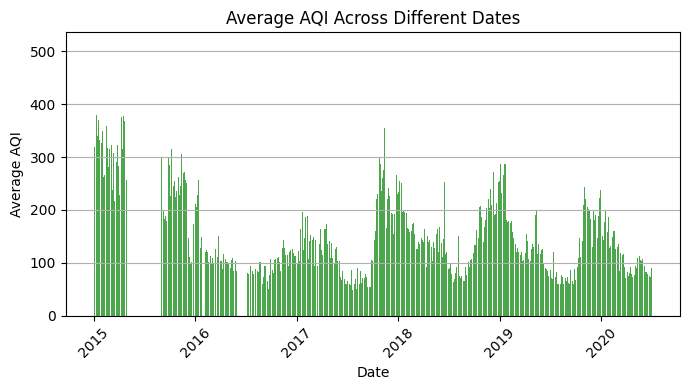

In [8]:
aqi_by_date = (
    cleaned_data.groupby('Date')['AQI']
    .mean()
    .reset_index()
)

plt.figure(figsize=(7,4))
plt.bar(
    aqi_by_date['Date'],
    aqi_by_date['AQI'],
    color='green',
    alpha=0.7
)

plt.xlabel('Date')
plt.ylabel('Average AQI')
plt.title('Average AQI Across Different Dates')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

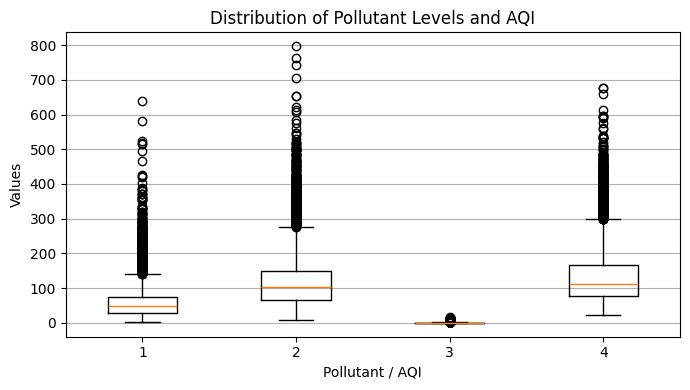

In [9]:
plt.figure(figsize=(7,4))

plt.boxplot(
    [
        cleaned_data['PM2.5'],
        cleaned_data['PM10'],
        cleaned_data['CO'],
        cleaned_data['AQI']
    ],
    label=['PM2.5', 'PM10', 'CO', 'AQI']
)

plt.xlabel('Pollutant / AQI')
plt.ylabel('Values')
plt.title('Distribution of Pollutant Levels and AQI')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

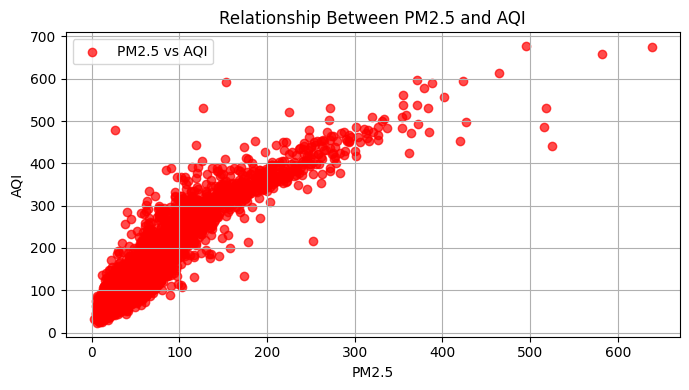

In [10]:
plt.figure(figsize=(7,4))

plt.scatter(
    cleaned_data['PM2.5'],
    cleaned_data['AQI'],
    alpha=0.7,
    color='red',
    label='PM2.5 vs AQI'
)

plt.xlabel('PM2.5')
plt.ylabel('AQI')
plt.title('Relationship Between PM2.5 and AQI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

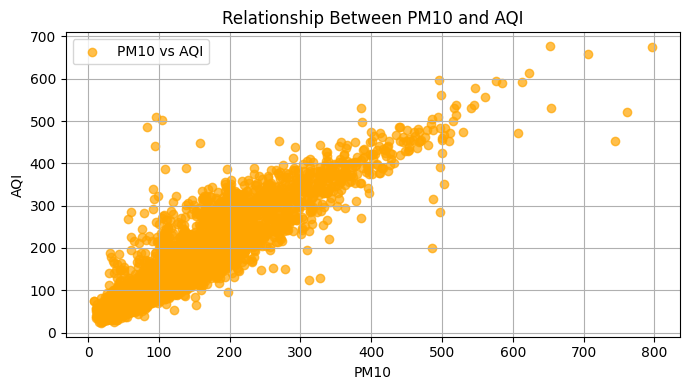

In [11]:
plt.figure(figsize=(7,4))

plt.scatter(
    cleaned_data['PM10'],
    cleaned_data['AQI'],
    alpha=0.7,
    color='orange',
    label='PM10 vs AQI'
)

plt.xlabel('PM10')
plt.ylabel('AQI')
plt.title('Relationship Between PM10 and AQI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

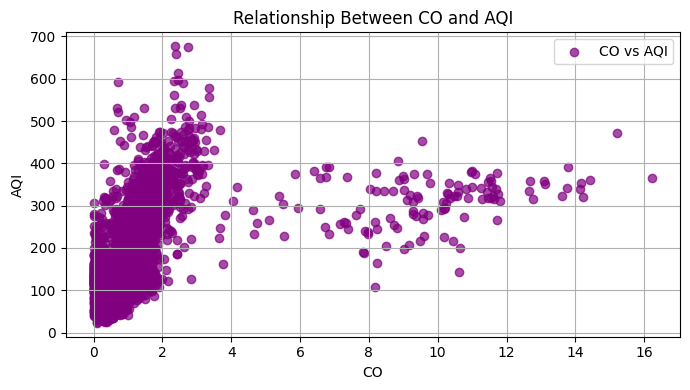

In [12]:
plt.figure(figsize=(7,4))

plt.scatter(
    cleaned_data['CO'],
    cleaned_data['AQI'],
    alpha=0.7,
    color='purple',
    label='CO vs AQI'
)

plt.xlabel('CO')
plt.ylabel('AQI')
plt.title('Relationship Between CO and AQI')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

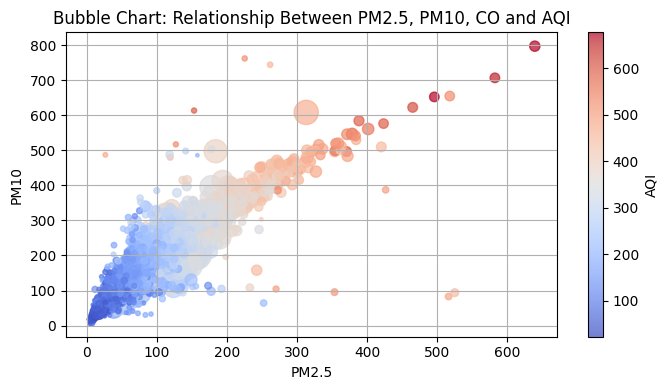

In [13]:
plt.figure(figsize=(7,4))

plt.scatter(
    cleaned_data['PM2.5'],
    cleaned_data['PM10'],
    s=cleaned_data['CO'] * 20,
    c=cleaned_data['AQI'],
    cmap='coolwarm',
    alpha=0.7
)

plt.xlabel('PM2.5')
plt.ylabel('PM10')
plt.title('Bubble Chart: Relationship Between PM2.5, PM10, CO and AQI')

plt.colorbar(label='AQI')

plt.grid(True)
plt.tight_layout()
plt.show()